# Lab 8-05：從評估結果到履歷，再到模擬面試

**目標**：把 8-01～8-03 實際跑出來的數字寫成履歷句子，並用程式檢查每個數字都有出處；
再做一個模擬面試官：從投影片的面試題抽題，用「限制、結構、數字」三心法替回答打分。

**你會學到**
- 一句好履歷＝做了什麼＋對照基準＋量化結果＋怎麼驗證
- 讓 LLM 潤稿之後，用程式抓「它自己編出來的數字」
- 課綱裡的範本數字和你自己量到的數字，必須分開標示
- 把 judge 換個量表，就變成面試練習的評審

**前置**：先跑過 8-01、8-02、8-03（本 notebook 讀它們存在 `runs/` 的結果）。原理見 `00_concepts.md` 第 8 節。

**對應投影片**：「履歷改寫前後」「AI 產業三層」「模組八面試題」「面試三心法總整理」「模組八小結」

![一句履歷的四個零件：做了什麼、對照基準、量化結果、怎麼驗證](images/resume_sentence.jpg)

*圖：左邊「熟悉 LangChain」看不出做過什麼；右邊一句話拆成四段，其中「量化結果」那段用虛線連到 `runs/` 的實測檔——數字一定要追得回出處。
這本前半段照這個格式產生履歷句子並查核數字，後半段換一個量表，讓 judge 當面試官。*

## Step 1：把前面跑出來的結果讀進來

所有數字都從檔案來，不手抄。這樣重跑實驗之後，履歷句子會跟著更新。

In [1]:
import json
from pathlib import Path

import pandas as pd

from course_utils.viz import setup_cjk

setup_cjk()
RUNS = Path("runs")


def load_run(name: str) -> pd.DataFrame:
    return pd.DataFrame(json.loads((RUNS / f"{name}.json").read_text(encoding="utf-8"))["rows"])


base, k1, v2 = load_run("baseline"), load_run("top_k_1"), load_run("prompt_v2")
calib = json.loads((RUNS / "judge_calibration.json").read_text(encoding="utf-8"))
trace = json.loads((RUNS / "trace_summary.json").read_text(encoding="utf-8"))


def no_answer_rate(df: pd.DataFrame) -> float:
    return df[df["tags"].map(lambda t: "無答案" in t)]["passed"].mean()


facts = {
    "題數": len(base),
    "人工標註數": calib["n"],
    "judge一致率": round(calib["一致率"] * 100),
    "基準通過率": round(base["passed"].mean() * 100),
    "k1通過率": round(k1["passed"].mean() * 100),
    "k1省token": round((1 - k1["gen_tokens"].mean() / base["gen_tokens"].mean()) * 100),
    "v2通過率": round(v2["passed"].mean() * 100),
    "基準無答案": round(no_answer_rate(base) * 100),
    "v2無答案": round(no_answer_rate(v2) * 100),
    "trace題數": trace["n"],
    "生成p50": round(trace["generate_p50_ms"]),
    "judge佔token": round(trace["judge_token_share"] * 100),
}
facts

{'題數': 40,
 '人工標註數': 10,
 'judge一致率': 70,
 '基準通過率': 60,
 'k1通過率': 60,
 'k1省token': 45,
 'v2通過率': 60,
 '基準無答案': 100,
 'v2無答案': 50,
 'trace題數': 12,
 '生成p50': 109,
 'judge佔token': 61}

## Step 2：壞履歷長什麼樣

「熟悉 LangChain，會調用 OpenAI API」——沒有問題、沒有對照、沒有數字，面試官看不出你做過什麼。
好句子有四個零件：

| 零件 | 問自己 |
|---|---|
| 做了什麼 | 我動了哪個環節？ |
| 對照基準 | 跟什麼比？基準版是什麼設定？ |
| 量化結果 | 指標從多少變多少？題庫多大？ |
| 怎麼驗證 | 別人怎麼重現？（題庫、judge 一致率、trace） |

## Step 3：用模板把實測數字填進句子

每句話都是 f-string，數字直接從 `facts` 來。有沒有過閘門，也由程式決定要寫哪一句。

In [2]:
k1_ok = facts["k1通過率"] >= facts["基準通過率"] - 2.5

resume = [
    f"建立 {facts['題數']} 題固定評估集與 LLM 評審（LLM 量表＋數字規則），"
    f"以 {facts['人工標註數']} 筆人工標註校準，評審與人工一致率 {facts['judge一致率']}%。",

    f"把回歸評估寫成 pytest 閘門，攔下一次「更親切」的 prompt 改版："
    f"資料外問題的正確拒答率由 {facts['基準無答案']}% 掉到 {facts['v2無答案']}%，"
    f"整體通過率 {facts['基準通過率']}% → {facts['v2通過率']}%。",

    (f"將檢索 top_k 由 3 降為 1，評估集通過率 {facts['基準通過率']}% → {facts['k1通過率']}%（未退步），"
     f"每題生成 token 減少 {facts['k1省token']}%。")
    if k1_ok else
    (f"評估把 top_k 由 3 降為 1 的省 token 方案（每題 −{facts['k1省token']}%），"
     f"因通過率 {facts['基準通過率']}% → {facts['k1通過率']}% 未過閘門而不採用。"),

    f"以 Langfuse 替檢索、生成、評審三步打點（{facts['trace題數']} 題），"
    f"量出生成 p50 延遲 {facts['生成p50']} ms，並發現評審佔總 token {facts['judge佔token']}%。",
]
for line in resume:
    print("•", line)

• 建立 40 題固定評估集與 LLM 評審（LLM 量表＋數字規則），以 10 筆人工標註校準，評審與人工一致率 70%。
• 把回歸評估寫成 pytest 閘門，攔下一次「更親切」的 prompt 改版：資料外問題的正確拒答率由 100% 掉到 50%，整體通過率 60% → 60%。
• 將檢索 top_k 由 3 降為 1，評估集通過率 60% → 60%（未退步），每題生成 token 減少 45%。
• 以 Langfuse 替檢索、生成、評審三步打點（12 題），量出生成 p50 延遲 109 ms，並發現評審佔總 token 61%。


注意第三句：沒過閘門也能寫成履歷——「我評估過、因為數據不支持而不採用」本身就是工程判斷。

## Step 4：讓 LLM 潤稿——然後抓它編的數字

很多人會把句子丟給模型「改得更專業」。先看會發生什麼：

In [3]:
import re

from course_utils.llm import chat

polished = chat([
    {"role": "system", "content": "你是履歷顧問。把使用者的履歷條列改寫得更專業、更有說服力，繁體中文，保持條列。"},
    {"role": "user", "content": "\n".join(resume)},
])
print(polished)

### 建立 40 個固定評估集與 LLM 評審（LLM 量表 + 數字規則），以 10 筆人工標註校準，評審與人工一致率達 70%。

### 將回歸評估寫成 pytest 閘門，攔下一次「更親切」的 prompt 改版：資料外問題的正確拒答率由 100% 掉到 50%，整體通過率從 60% 提升至 60%。

### 將檢索 top_k 由 3 降為 1，評估集通過率從 60% 保持在 60%，每題生成 token 減少約 45%。

### 使用 Langfuse 替檢索、生成、評審三步打點（12 個題），量出生成 p50 延遲約 109 毫秒，並發現評審佔總 token 61%。


查核規則跟 8-01 的數字規則一樣簡單：潤稿後出現的每個數字，都必須出現在原句裡（也就是追得回 `runs/`）。

In [4]:
def numbers_in(text: str) -> set[str]:
    return {n.replace(",", "") for n in re.findall(r"\d[\d,]*(?:\.\d+)?", text)}


allowed = numbers_in("\n".join(resume))
invented = numbers_in(polished) - allowed
missing = allowed - numbers_in(polished)
print("潤稿後多出來、查不到出處的數字：", invented or "無")
print("潤稿後不見的數字：              ", missing or "無")

潤稿後多出來、查不到出處的數字： 無
潤稿後不見的數字：               無


3B 模型潤稿時常見三種狀況：數字被改掉、加上「顯著提升 30%」之類的新數字、或把數字整個刪掉變成形容詞。
不管哪種，**有查不到出處的數字就不能用**；數字被刪掉的也要補回來。

## Step 5：實測數字 vs 課綱範本數字

課綱與投影片「履歷改寫前後」裡的數字（Top-3 召回 68%→91%、根因命中 55%→80% 等）是**範本**，
不是任何人實測出來的（來源見 `docs/slides/sources/product-facts.md` 第 8 條）。
它們的用途是示範句型；寫進你自己的履歷之前，要換成你自己的評估集量出來的數字。

In [5]:
template = pd.DataFrame([
    ("檢索 Top-3 召回", "68% → 91%", "範本（課綱，非實測）"),
    ("根因命中率（40 件事故）", "55% → 80%", "範本（課綱，非實測）"),
    ("未經核准的寫入", "120 次中 0 次", "範本（課綱，非實測）"),
    ("單次調查 Token", "−38%", "範本（課綱，非實測）"),
    ("評審與人工一致率", f"{facts['judge一致率']}%（{facts['人工標註數']} 筆）", "本模組實測"),
    ("prompt v2 資料外拒答率", f"{facts['基準無答案']}% → {facts['v2無答案']}%", "本模組實測"),
    ("top_k 3→1 通過率", f"{facts['基準通過率']}% → {facts['k1通過率']}%", "本模組實測"),
    ("top_k 3→1 生成 token", f"−{facts['k1省token']}%", "本模組實測"),
], columns=["指標", "數字", "來源"])
template

,指標,數字,來源
0,檢索 Top-3 召回,68% → 91%,範本（課綱，非實測）
1,根因命中率（40 件事故）,55% → 80%,範本（課綱，非實測）
2,未經核准的寫入,120 次中 0 次,範本（課綱，非實測）
3,單次調查 Token,−38%,範本（課綱，非實測）
4,評審與人工一致率,70%（10 筆）,本模組實測
5,prompt v2 資料外拒答率,100% → 50%,本模組實測
6,top_k 3→1 通過率,60% → 60%,本模組實測
7,top_k 3→1 生成 token,−45%,本模組實測


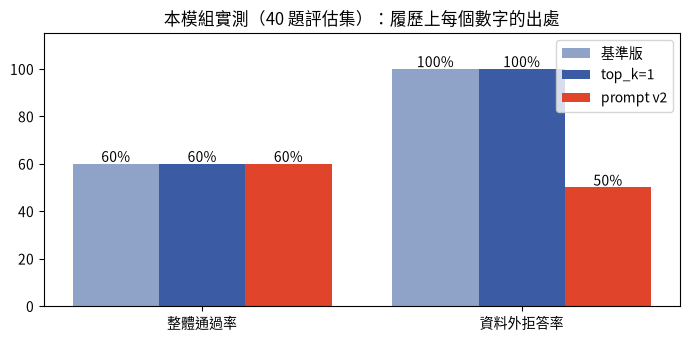

In [6]:
import matplotlib.pyplot as plt

labels = ["整體通過率", "資料外拒答率"]
values = {
    "基準版": [facts["基準通過率"], facts["基準無答案"]],
    "top_k=1": [facts["k1通過率"], no_answer_rate(k1) * 100],
    "prompt v2": [facts["v2通過率"], facts["v2無答案"]],
}
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, (name, vals) in enumerate(values.items()):
    bars = ax.bar([x + (i - 1) * 0.27 for x in range(2)], vals, 0.27, label=name,
                  color=["#8fa3c8", "#3b5ba5", "#e0442b"][i])
    ax.bar_label(bars, fmt="%.0f%%")
ax.set_xticks([0, 1], labels)
ax.set_ylim(0, 115)
ax.set_title(f"本模組實測（{facts['題數']} 題評估集）：履歷上每個數字的出處")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

面試時被追問「這個數字怎麼量的」，你要能指著這張圖說：題庫幾題、基準是什麼、judge 跟人工一致率多少。
本模組的已知限制也要主動講：受測系統和 judge 是同一個 3B 模型、題庫是自寫的虛構 FAQ、題數只有 40。

## Step 6：面試題庫——直接取自投影片

`data/interview_questions.json` 是從投影片模組 1～8 的面試題頁抽出來的 21 題（`190-interview` … `880-interview`）。

In [7]:
questions = json.loads(Path("data/interview_questions.json").read_text(encoding="utf-8"))
qdf = pd.DataFrame(questions)
print(qdf.groupby("module").size().to_dict())
qdf[qdf["module"] == 8]

{1: 2, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 2, 8: 2}


,module,slide,question
19,8,模組八面試題,生產環境中，如何評估與降低大模型應用的幻覺？
20,8,模組八面試題,面對長流程、多工具的複雜 Agent 任務，如何保證執行穩定？


## Step 7：面試官 judge——三心法量表

投影片「面試三心法總整理」：面試官要聽的是**限制、結構、數字**。
把 8-01 的 judge 寫法搬過來，只換量表：三個維度各 1～5 分，先寫理由，再給一句改進建議。

In [8]:
from pydantic import BaseModel, Field

from mini_rag import MODEL, client


class InterviewScore(BaseModel):
    reason: str
    限制: int = Field(ge=1, le=5)
    結構: int = Field(ge=1, le=5)
    數字: int = Field(ge=1, le=5)
    建議: str


INTERVIEWER = """你是 AI 應用工程師職缺的面試官，依三個維度替求職者的回答打分，每個 1 到 5 分。

限制：有沒有主動講出模型或方法的限制（幻覺、context 長度、工具呼叫不穩、評審偏誤），以及怎麼兜底。
  1 = 把大模型講成萬能；3 = 提到限制但沒講怎麼處理；5 = 講出具體限制和對應的工程手段。
結構：有沒有講清楚系統怎麼分層、每層負責什麼，而不是只說「我做了一個聊天機器人」。
  1 = 只有功能描述；3 = 有提到元件但沒講關係；5 = 分層清楚、說得出每層的取捨。
數字：有沒有用指標佐證，而且講得出對照基準和量法（題庫大小、基準版、怎麼評）。
  1 = 沒有任何數字；3 = 有數字但沒有基準或量法；5 = 數字、基準、量法都有。

輸出欄位：reason（一句話總評）、限制、結構、數字（各 1～5）、建議（一句最該補的地方）。"""


def interview_score(question: str, answer: str, retries: int = 2) -> InterviewScore:
    for _ in range(retries + 1):
        resp = client().chat.completions.parse(   # 跟 judge.py 一樣用結構化輸出
            model=MODEL, temperature=0, response_format=InterviewScore,
            messages=[{"role": "system", "content": INTERVIEWER},
                      {"role": "user", "content": f"面試題：{question}\n求職者回答：{answer}"}],
        )
        if resp.choices[0].message.parsed is not None:
            return resp.choices[0].message.parsed
    raise RuntimeError("面試官 judge 輸出格式連續不合格")

## Step 8：同一題，兩種回答

題目取自「模組八面試題」：生產環境中，如何評估與降低大模型應用的幻覺？
弱回答是面試官聽膩的說法；強回答按投影片的回答維度由外到內講，數字用的是**本模組實測**的結果。

In [9]:
q8 = qdf[qdf["module"] == 8].iloc[0]["question"]

weak = "大模型現在很強，幻覺已經很少了。我會用最新的模型，然後把 prompt 寫好，叫它不要亂講，基本上就沒問題。"

strong = (
    f"幻覺擋不掉，只能分層降低並量出來。結構上分四層：提示詞要求資料外就說沒有；檢索用混合召回加重排提高相關性；"
    f"生成後用 LLM 評審對照參考答案，再加數字比對的程式規則，因為我發現 3B 評審會漏看數字；高風險操作走審批。"
    f"評估方面，我用 {facts['題數']} 題固定題庫做回歸測試，評審先用 {facts['人工標註數']} 筆人工標註校準，一致率 {facts['judge一致率']}%。"
    f"有一次同事把 prompt 改得更親切，資料外問題的正確拒答率從 {facts['基準無答案']}% 掉到 {facts['v2無答案']}%，被 pytest 閘門擋下。"
    f"限制是題庫只有 {facts['題數']} 題、評審和受測系統是同一個小模型，所以我會再抽樣做人工複查。"
)
print(q8, "\n")
scores = {"弱回答": interview_score(q8, weak), "強回答": interview_score(q8, strong)}
for name, s in scores.items():
    print(f"{name}：限制 {s.限制}、結構 {s.結構}、數字 {s.數字}｜{s.reason}\n  建議：{s.建議}")

生產環境中，如何評估與降低大模型應用的幻覺？ 

弱回答：限制 1、結構 1、數字 1｜求職者只講了大模型的強大，沒有提到任何具體的限制和解決方案。
  建議：求職者可以補充具體的限制，例如模型的語義理解能力有限、prompt 需要精確設計等，並提出相應的解決方案，如使用更細分的prompt、增加題庫大小等。
強回答：限制 3、結構 5、數字 3｜求職者回答清晰地分層解決問題，並提供了具體的解決方案和評估方法。
  建議：求職者可以提供更多的數字支持，例如具體的回歸測試結果和人工複查的細節。


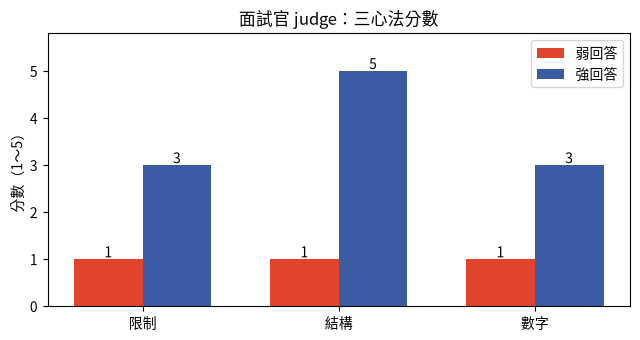

In [10]:
import numpy as np

dims = ["限制", "結構", "數字"]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for i, (name, s) in enumerate(scores.items()):
    vals = [getattr(s, d) for d in dims]
    bars = ax.bar(np.arange(3) + (i - 0.5) * 0.35, vals, 0.35, label=name,
                  color=["#e0442b", "#3b5ba5"][i])
    ax.bar_label(bars)
ax.set_xticks(range(3), dims)
ax.set_ylim(0, 5.8)
ax.set_ylabel("分數（1～5）")
ax.set_title("面試官 judge：三心法分數")
ax.legend()
plt.tight_layout()
plt.show()

這個面試官也是 3B 模型，分數只是參考；真正有用的是「建議」那一行，以及你自己對照三心法逐句檢查。
跟 8-01 一樣，想認真用它，就先拿幾份你自己標過分的回答校準它。

## Step 9：隨機抽題練習

把抽題、作答、評分包成一個函式。在 notebook 裡用一段示範回答；你練習時把 `my_answer` 換成自己的。

In [11]:
import random


def mock_interview(answer: str, seed: int | None = None) -> dict:
    q = random.Random(seed).choice(questions)
    s = interview_score(q["question"], answer)
    print(f"【{q['slide']}】{q['question']}")
    print(f"限制 {s.限制}／結構 {s.結構}／數字 {s.數字}　總評：{s.reason}")
    print(f"建議：{s.建議}")
    return q


my_answer = (
    "要看資料多常變、需要的是知識還是格式。常變的知識用 RAG，因為更新文件就好、還能附出處；"
    "要固定輸出格式或語氣才考慮 LoRA 微調。兩者可以結合：RAG 負責內容，微調讓小模型學會照格式回答。"
    "我在課程裡用 40 題題庫比較過不同設定，但微調這部分還沒有自己量過數字。"
)
_ = mock_interview(my_answer, seed=9)  # seed=9 抽到模組六「RAG 還是微調」，跟示範回答對得上

【模組六面試題】面對企業垂直問答，怎麼決定用 RAG 還是微調？兩者怎麼結合？
限制 3／結構 3／數字 1　總評：回答清晰但缺乏具體數字和工程手段
建議：補充具體的數字和工程手段，例如微調的測試結果和對比基準


## 試試看

1. 把 Step 8 強回答的最後一句（限制）刪掉，重新打分。「限制」分數有掉嗎？
2. 在 Step 4 的潤稿 system prompt 加一句「不得新增或修改任何數字」，再查核一次。查到的編造數字有變少嗎？還需要程式查核嗎？
3. 換 `seed` 抽三題，各寫一段回答，記下三心法分數最低的維度，那就是你下一輪要補的地方。

## 小結

- 履歷句子＝做了什麼＋對照基準＋量化結果＋怎麼驗證；數字從 `runs/` 自動帶入，不手抄。
- LLM 潤稿會動數字，用程式查核每個數字的出處；課綱的範本數字只能當句型，要換成自己的實測值。
- 換個量表，judge 就變成面試官。模組 8 到這裡結束，回到投影片「模組八小結」與「面試三心法總整理」，把評估、trace、履歷與面試串起來。